In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# Load the cleaned dataset from the project directory

data_path = Path("../Data/processed/smartphones_clean.csv")
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

Dataset shape: (1020, 31)
Columns: ['model', 'url', 'brand', 'scrape_date', 'price_inr', 'spec_score', 'processor_name', 'cpu_cores', 'cpu_ghz', 'ram_gb', 'storage_gb', 'battery_mah', 'fast_charge_w', 'charging_status', 'screen_in', 'res_short', 'res_long', 'refresh_hz', 'rear_main_mp', 'rear_mp_value_count', 'front_mp', 'os_family', 'os_major', 'is_feature_phone', 'is_legacy_os', 'in_analysis_scope', 'is_foldable', 'is_5g', 'has_nfc', 'has_esim', 'has_memory_card']


## 1. Distribution of Smartphone Prices

Examine the distribution of listed smartphone prices to understand the price range, concentration of observations, and potential right skew.

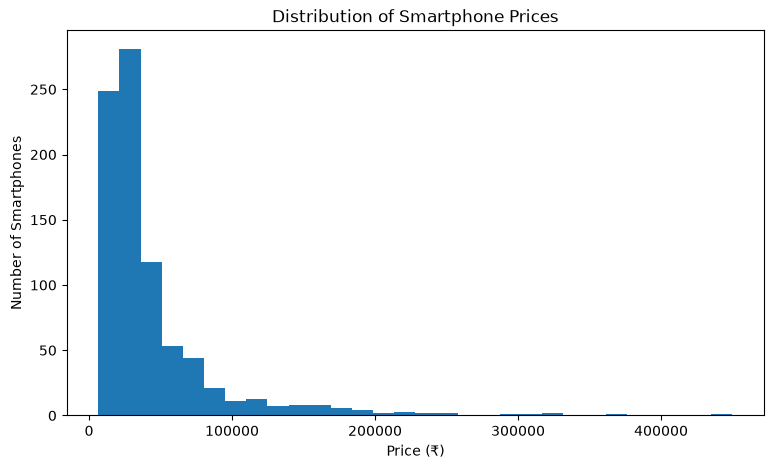

In [3]:
# Filter smartphones in the analysis scope
prices = df.loc[df["in_analysis_scope"], "price_inr"].dropna()

# Plot price distribution
plt.figure(figsize=(9, 5))
plt.hist(prices, bins=30)

plt.title("Distribution of Smartphone Prices")
plt.xlabel("Price (₹)")
plt.ylabel("Number of Smartphones")

plt.show()

## 2. Top 10 Smartphone Brands

Compare the number of smartphone models available from each of the top 10 brands in the analysis dataset.

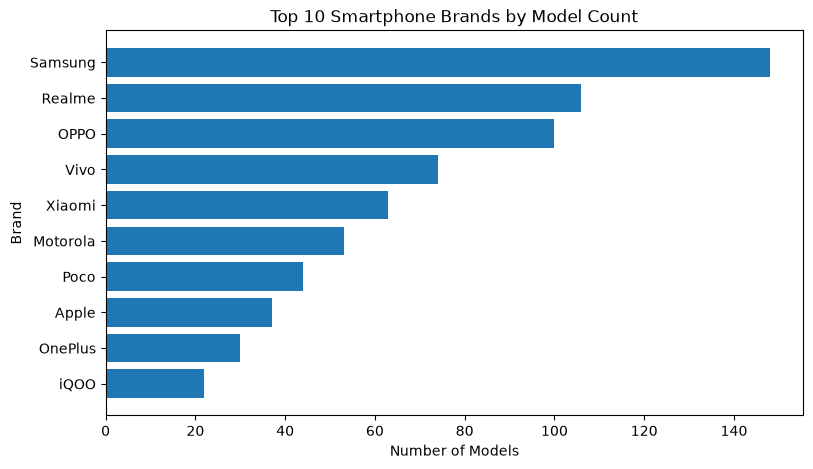

In [4]:
# Count smartphones by brand
brand_counts = (
    df.loc[df["in_analysis_scope"], "brand"]
    .value_counts()
    .head(10)
    .sort_values()
)

# Plot
plt.figure(figsize=(9, 5))
plt.barh(brand_counts.index, brand_counts.values)

plt.title("Top 10 Smartphone Brands by Model Count")
plt.xlabel("Number of Models")
plt.ylabel("Brand")

plt.show()

## 3. Median Smartphone Price by Brand

Compare the median listed price across the 10 brands with the most models in the dataset.

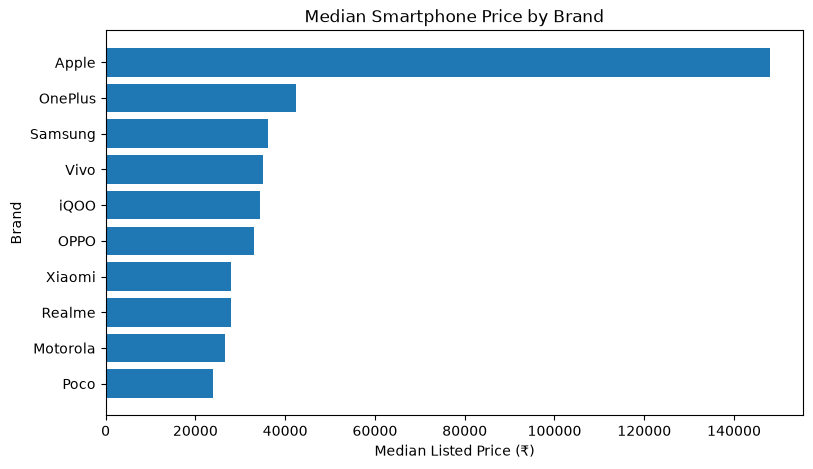

In [5]:
# Find the 10 brands with the most models
top_brands = (
    df.loc[df["in_analysis_scope"], "brand"]
    .value_counts()
    .head(10)
    .index
)

# Calculate median price for each brand
median_prices = (
    df.loc[
        df["in_analysis_scope"] & df["brand"].isin(top_brands)
    ]
    .groupby("brand")["price_inr"]
    .median()
    .sort_values()
)

# Plot
plt.figure(figsize=(9, 5))
plt.barh(median_prices.index, median_prices.values)

plt.title("Median Smartphone Price by Brand")
plt.xlabel("Median Listed Price (₹)")
plt.ylabel("Brand")

plt.show()

## 4. Median Smartphone Price by RAM

Compare median listed prices across smartphone RAM configurations to explore the relationship between RAM capacity and price.

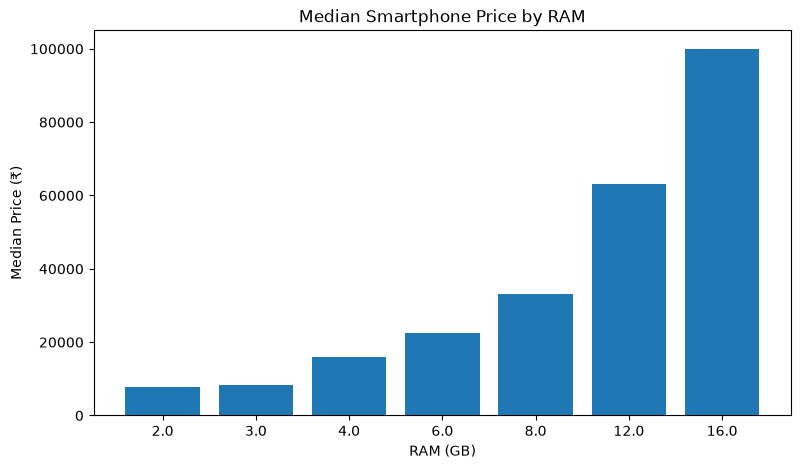

In [6]:
# Calculate median price by RAM
ram_prices = df[df["in_analysis_scope"]].dropna(
    subset=["ram_gb", "price_inr"]
)

median_price = (
    ram_prices.groupby("ram_gb")["price_inr"]
    .median()
    .sort_index()
)

# Plot
plt.figure(figsize=(9, 5))
plt.bar(median_price.index.astype(str), median_price.values)

plt.title("Median Smartphone Price by RAM")
plt.xlabel("RAM (GB)")
plt.ylabel("Median Price (₹)")

plt.show()

## 5. Spec Score vs. Smartphone Price

Explore the relationship between Smartprix's specification score and listed smartphone price.

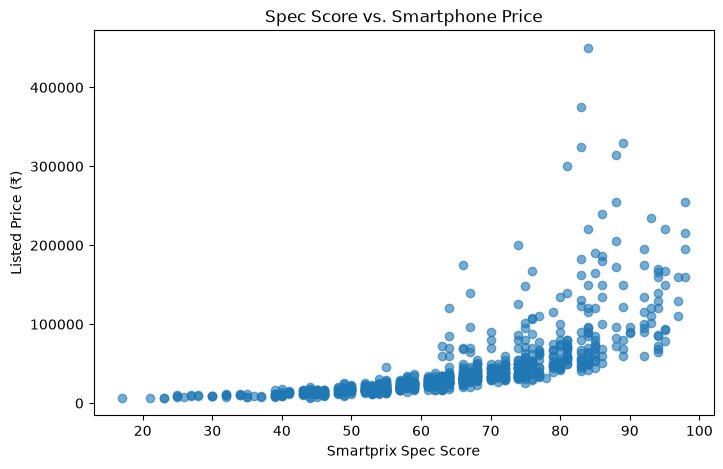

In [7]:
# Select smartphones in the analysis scope
phones = df[df["in_analysis_scope"]].dropna(
    subset=["spec_score", "price_inr"]
)

# Plot
plt.figure(figsize=(8, 5))
plt.scatter(phones["spec_score"], phones["price_inr"], alpha=0.6)

plt.title("Spec Score vs. Smartphone Price")
plt.xlabel("Smartprix Spec Score")
plt.ylabel("Listed Price (₹)")

plt.show()

## 6. Storage Capacity vs. Smartphone Price

Examine how median smartphone prices vary across storage capacities to identify whether higher storage is associated with higher listed prices.

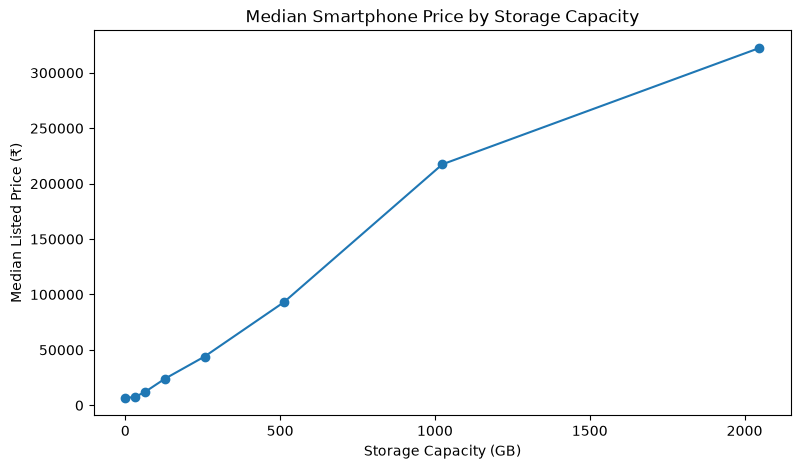

In [8]:
phones = df.loc[
    df["in_analysis_scope"]
].dropna(subset=["storage_gb", "price_inr"])

median_prices = (
    phones.groupby("storage_gb")["price_inr"]
    .median()
    .sort_index()
)

plt.figure(figsize=(9, 5))
plt.plot(median_prices.index, median_prices.values, marker="o")
plt.title("Median Smartphone Price by Storage Capacity")
plt.xlabel("Storage Capacity (GB)")
plt.ylabel("Median Listed Price (₹)")
plt.show()

## 7. Median Smartphone Price by 5G Availability

Compare median listed prices for 5G and non-5G smartphones to examine their price difference.

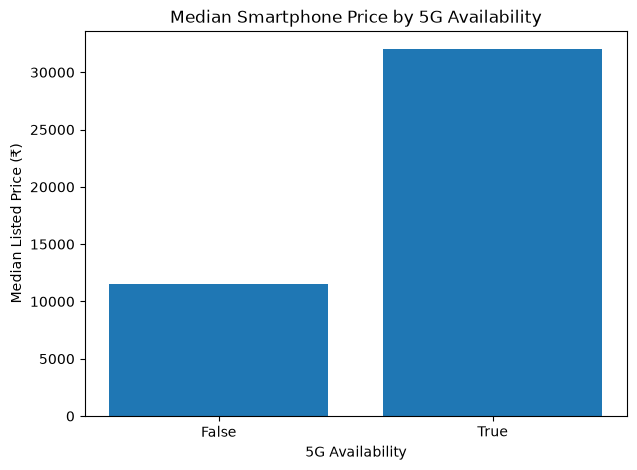

In [9]:
phones = df.loc[df["in_analysis_scope"]].dropna(
    subset=["is_5g", "price_inr"]
)

median_prices = phones.groupby("is_5g")["price_inr"].median()

plt.figure(figsize=(7, 5))
plt.bar(median_prices.index.astype(str), median_prices.values)
plt.title("Median Smartphone Price by 5G Availability")
plt.xlabel("5G Availability")
plt.ylabel("Median Listed Price (₹)")
plt.show()

## 8. Median Smartphone Price by Operating System

Compare median listed prices across operating system families to examine differences in price positioning.

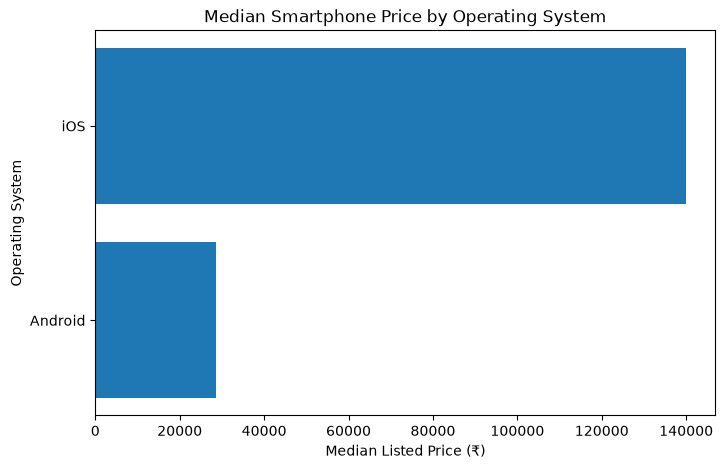

In [10]:
phones = df.loc[df["in_analysis_scope"]].dropna(
    subset=["os_family", "price_inr"]
)

median_prices = (
    phones.groupby("os_family")["price_inr"]
    .median()
    .sort_values()
)

plt.figure(figsize=(8, 5))
plt.barh(median_prices.index, median_prices.values)
plt.title("Median Smartphone Price by Operating System")
plt.xlabel("Median Listed Price (₹)")
plt.ylabel("Operating System")
plt.show()

## 9. Median Smartphone Price by Foldable Status

Compare median listed prices of foldable and non-foldable smartphones to examine whether foldable devices occupy a different price segment.

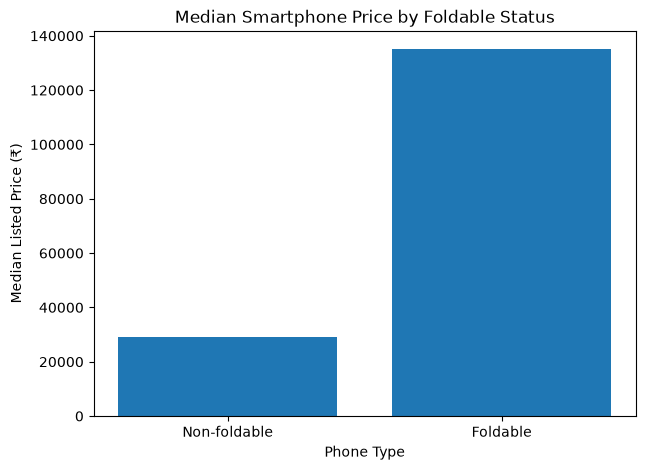

               median  count
is_foldable                 
False         28995.0    801
True         134999.0     37


In [11]:
phones = df.loc[df["in_analysis_scope"]].dropna(
    subset=["is_foldable", "price_inr"]
)

summary = phones.groupby("is_foldable")["price_inr"].agg(
    ["median", "count"]
)

labels = ["Non-foldable" if not x else "Foldable" for x in summary.index]

plt.figure(figsize=(7, 5))
plt.bar(labels, summary["median"])
plt.title("Median Smartphone Price by Foldable Status")
plt.xlabel("Phone Type")
plt.ylabel("Median Listed Price (₹)")
plt.show()

print(summary)

## 10. Correlation of Numeric Features with Price

Compare the correlations between numeric smartphone features and listed price to identify which features have the strongest linear relationships with price.

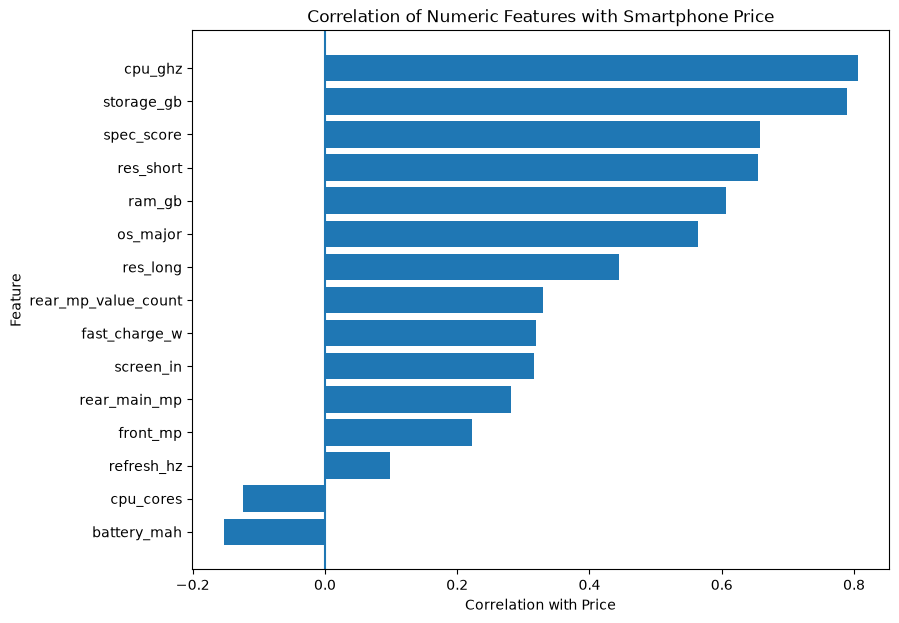

In [12]:
phones = df.loc[df["in_analysis_scope"]]

numeric_data = phones.select_dtypes(include="number")

price_corr = (
    numeric_data.corr()["price_inr"]
    .drop("price_inr")
    .sort_values()
)

plt.figure(figsize=(9, 7))
plt.barh(price_corr.index, price_corr.values)
plt.axvline(0)
plt.title("Correlation of Numeric Features with Smartphone Price")
plt.xlabel("Correlation with Price")
plt.ylabel("Feature")
plt.show()

## 11. Smartphone Price Range Across Major Brands

Compare price distributions across the eight most represented brands to examine within-brand price variation and potential premium-priced models.

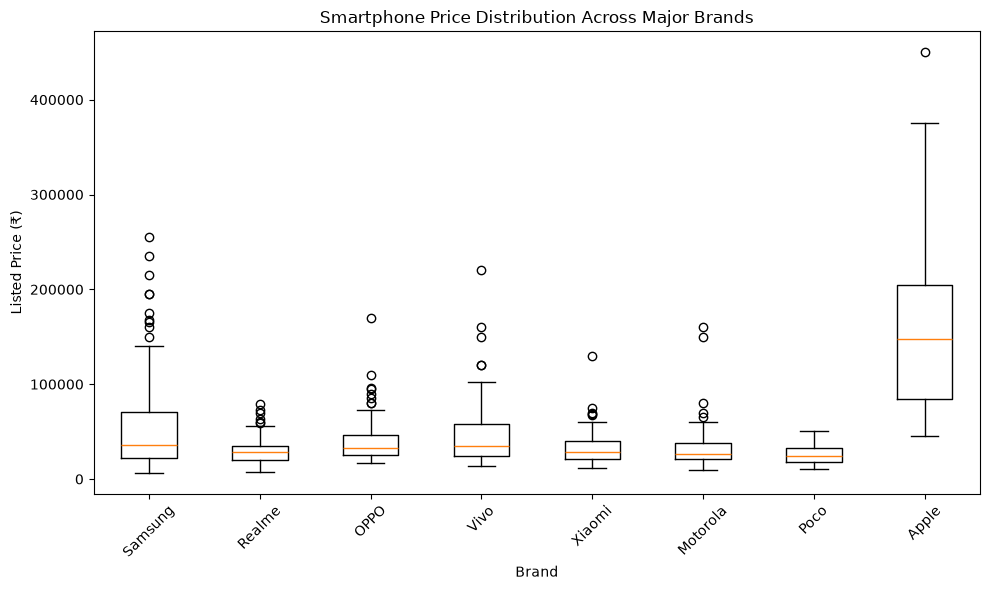

In [13]:
phones = df.loc[df["in_analysis_scope"]].dropna(
    subset=["brand", "price_inr"]
)

top_brands = phones["brand"].value_counts().head(8).index

brand_prices = [
    phones.loc[phones["brand"] == brand, "price_inr"]
    for brand in top_brands
]

plt.figure(figsize=(10, 6))
plt.boxplot(brand_prices, tick_labels=top_brands)
plt.title("Smartphone Price Distribution Across Major Brands")
plt.xlabel("Brand")
plt.ylabel("Listed Price (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
from pathlib import Path

file_path = Path("Data/processed/ridge_test_predictions.csv")

if not file_path.exists():
    file_path = Path("../Data/processed/ridge_test_predictions.csv")

predictions = pd.read_csv(file_path)

## 12. Actual vs. Predicted Smartphone Prices

Compare actual and predicted prices on the held-out test set. Points closer to the diagonal line indicate more accurate predictions.

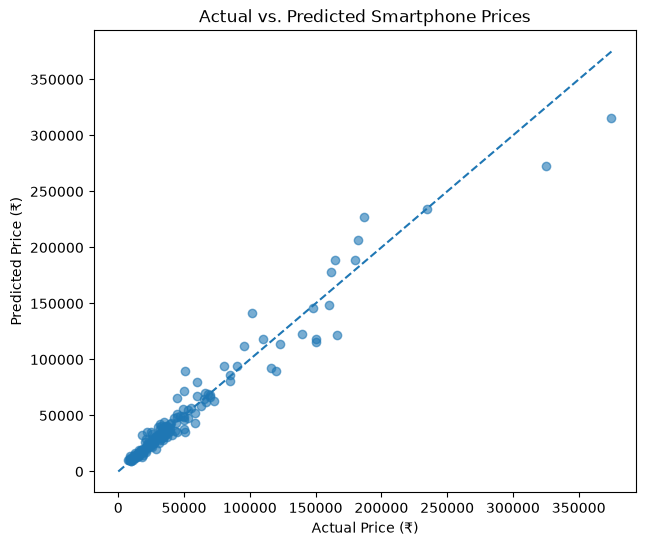

In [15]:
predictions = pd.read_csv(
    "../Data/processed/ridge_test_predictions.csv"
)

limit = max(
    predictions["actual_price"].max(),
    predictions["predicted_price"].max()
)

plt.figure(figsize=(7, 6))
plt.scatter(
    predictions["actual_price"],
    predictions["predicted_price"],
    alpha=0.6
)
plt.plot([0, limit], [0, limit], linestyle="--")

plt.title("Actual vs. Predicted Smartphone Prices")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.show()

## 13. Prediction Errors vs. Actual Price

Examine whether prediction errors vary with actual smartphone prices and identify possible patterns of overprediction or underprediction.

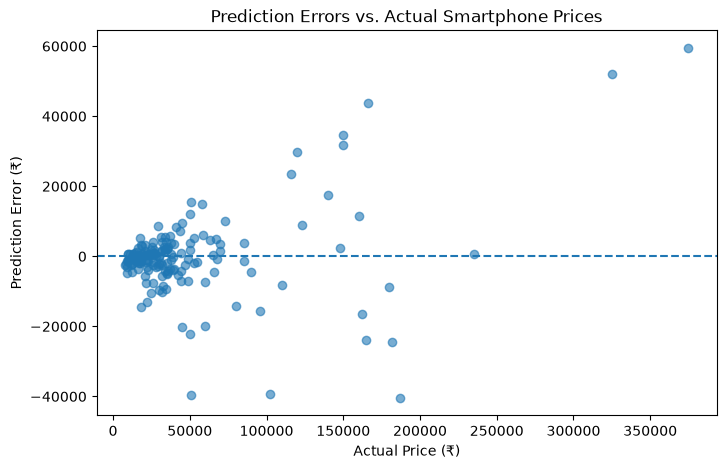

In [16]:
residuals = (
    predictions["actual_price"] - predictions["predicted_price"]
)

plt.figure(figsize=(8, 5))
plt.scatter(
    predictions["actual_price"],
    residuals,
    alpha=0.6
)
plt.axhline(0, linestyle="--")

plt.title("Prediction Errors vs. Actual Smartphone Prices")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Prediction Error (₹)")
plt.show()

## 14. Prediction Error by Smartphone Price Segment

Compare mean absolute prediction errors across budget, mid-range, upper-mid-range, and premium smartphones to identify which price segments are harder for the model to predict accurately.

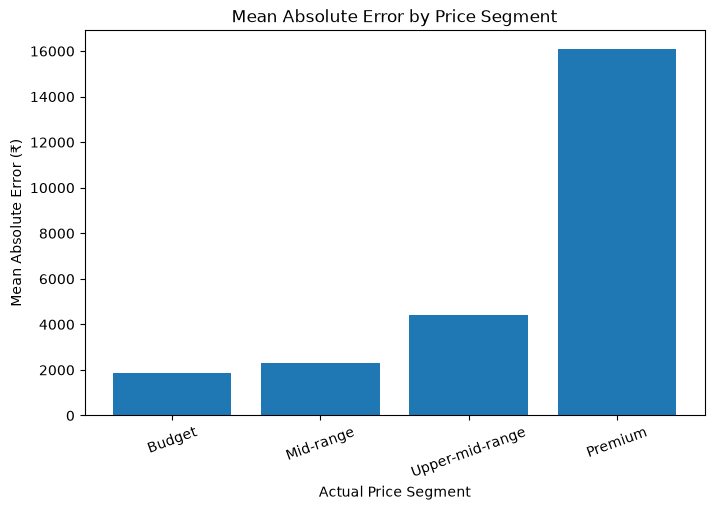

In [17]:
errors = predictions.copy()

errors["absolute_error"] = (
    errors["actual_price"] - errors["predicted_price"]
).abs()

errors["price_segment"] = pd.cut(
    errors["actual_price"],
    bins=[0, 10000, 25000, 50000, float("inf")],
    labels=["Budget", "Mid-range", "Upper-mid-range", "Premium"]
)

segment_mae = errors.groupby(
    "price_segment", observed=False
)["absolute_error"].mean()

plt.figure(figsize=(8, 5))
plt.bar(segment_mae.index, segment_mae.values)
plt.title("Mean Absolute Error by Price Segment")
plt.xlabel("Actual Price Segment")
plt.ylabel("Mean Absolute Error (₹)")
plt.xticks(rotation=20)
plt.show()

## 15. Mean Absolute Percentage Error by Price Segment

Compare average percentage prediction errors across smartphone price segments to identify where the model is relatively less accurate.

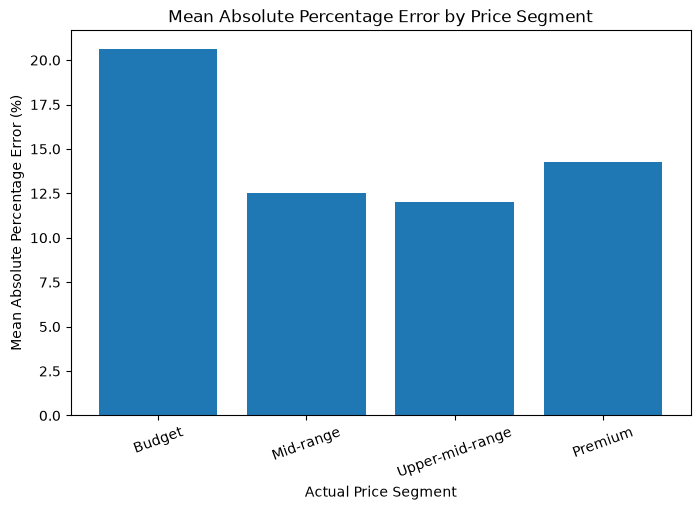

Test phones per segment:
price_segment
Budget             10
Mid-range          53
Upper-mid-range    64
Premium            41
Name: count, dtype: int64


In [18]:
errors = predictions.copy()

errors["absolute_percentage_error"] = (
    (errors["actual_price"] - errors["predicted_price"]).abs()
    / errors["actual_price"] * 100
)

errors["price_segment"] = pd.cut(
    errors["actual_price"],
    bins=[0, 10000, 25000, 50000, float("inf")],
    labels=["Budget", "Mid-range", "Upper-mid-range", "Premium"]
)

segment_mape = errors.groupby(
    "price_segment", observed=False
)["absolute_percentage_error"].mean()

plt.figure(figsize=(8, 5))
plt.bar(segment_mape.index, segment_mape.values)
plt.title("Mean Absolute Percentage Error by Price Segment")
plt.xlabel("Actual Price Segment")
plt.ylabel("Mean Absolute Percentage Error (%)")
plt.xticks(rotation=20)
plt.show()

print("Test phones per segment:")
print(errors["price_segment"].value_counts().sort_index())